# Component A Analysis: Perception, Planning & Control

This notebook generates all required visualizations and analysis for Component A of the ASR700 assignment.

## Required Outputs:
1. Sensor perception pipeline visualization
2. Occupancy grid map
3. Dijkstra vs A* path comparison
4. PID controller response curves
5. Planned vs actual trajectory
6. Performance evaluation table

In [1]:
# Setup and imports
import sys
import os

# Project root detection: works whether the kernel starts in this notebook's
# folder or in the python_analysis/ folder
if os.path.isdir(os.path.abspath('../../webots_project')):
    PROJECT_ROOT = os.path.abspath('../..')   # started inside component_*_analysis/
else:
    PROJECT_ROOT = os.path.abspath('..')      # started inside python_analysis/

PLOTS_DIR = os.path.join(PROJECT_ROOT, 'plots')
os.makedirs(PLOTS_DIR, exist_ok=True)

sys.path.insert(0, os.path.join(PROJECT_ROOT, 'webots_project', 'controllers', 'robot_controller_a'))
sys.path.insert(0, os.path.join(PROJECT_ROOT, 'python_analysis', 'utils'))
sys.path.insert(0, PROJECT_ROOT)  # enables 'python_analysis' package imports

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd
from typing import List, Tuple

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
print("Setup complete")

Setup complete


In [2]:
# Import our modules
from helpers import *
from config import *
from perception import *
from planning import *
from control import *
from kinematics import *

print("Modules imported successfully")

Modules imported successfully


## 1. Sensor Perception Pipeline Visualization

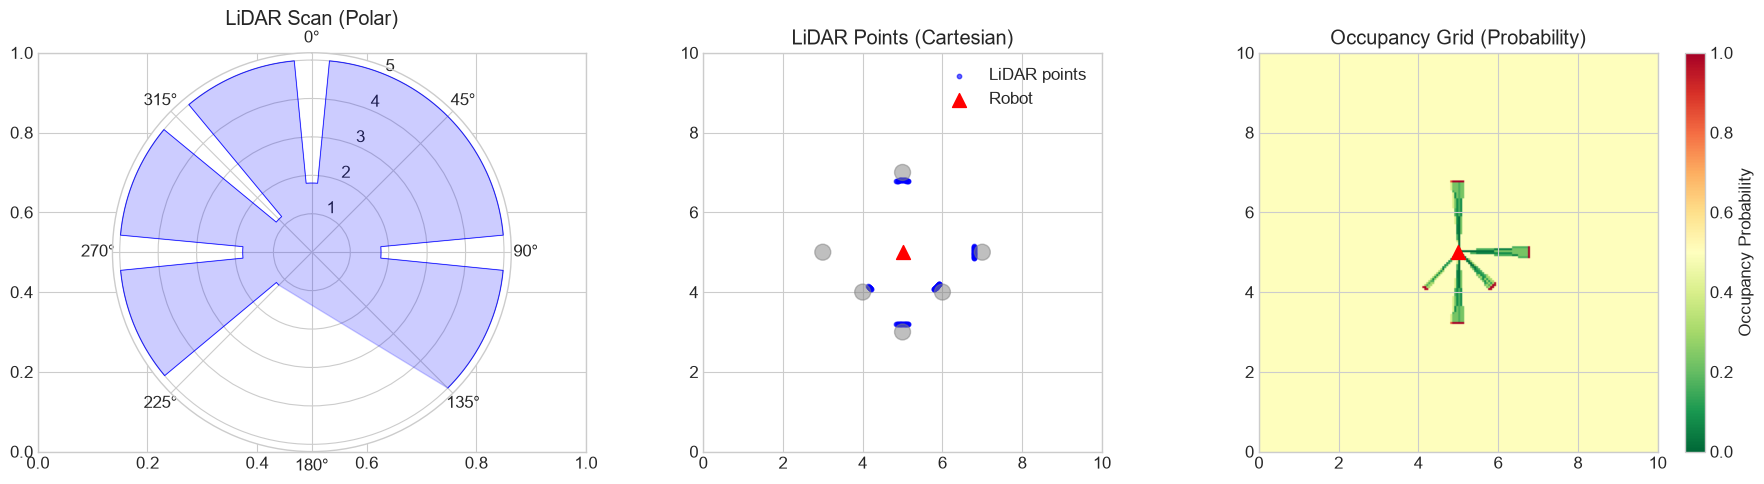

In [3]:
# Create synthetic sensor data for visualization
sensor_config = SensorConfig()
env_config = EnvironmentConfig()
robot_config = RobotConfig()

# Simulate LiDAR scan in environment with obstacles
num_beams = int(sensor_config.lidar_fov / sensor_config.lidar_resolution)
angles = np.linspace(-np.deg2rad(sensor_config.lidar_fov/2), 
                     np.deg2rad(sensor_config.lidar_fov/2), num_beams)

# Robot at center, obstacles at various positions
robot_pos = (5.0, 5.0)
robot_heading = 0.0

# Generate synthetic LiDAR with obstacles
ranges = np.full(num_beams, sensor_config.lidar_max_range)

# Add obstacles
obstacles = [
    (3.0, 5.0),   # Left
    (7.0, 5.0),   # Right
    (5.0, 3.0),   # Front
    (5.0, 7.0),   # Back
    (4.0, 4.0),   # Front-left
    (6.0, 4.0),   # Front-right
]

for i, angle in enumerate(angles):
    global_angle = robot_heading + angle
    min_dist = sensor_config.lidar_max_range
    for ox, oy in obstacles:
        # Ray-obstacle intersection (simplified)
        dx = ox - robot_pos[0]
        dy = oy - robot_pos[1]
        dist = np.hypot(dx, dy)
        bearing = np.arctan2(dy, dx)
        angle_diff = normalize_angle(bearing - global_angle)
        if abs(angle_diff) < np.deg2rad(5):  # Within beam width
            min_dist = min(min_dist, dist - 0.2)  # Obstacle radius
    ranges[i] = min(min_dist, sensor_config.lidar_max_range)

# Visualize LiDAR
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Polar plot of LiDAR
ax = axes[0]
ax = plt.subplot(131, projection='polar')
ax.plot(angles, ranges, 'b-', linewidth=0.5)
ax.fill(angles, ranges, alpha=0.2, color='blue')
ax.set_title('LiDAR Scan (Polar)', pad=20)
ax.set_theta_zero_location('N')
ax.set_theta_direction(-1)

# Cartesian points
ax = axes[1]
valid = ranges < sensor_config.lidar_max_range
if np.any(valid):
    xs = robot_pos[0] + ranges[valid] * np.cos(robot_heading + angles[valid])
    ys = robot_pos[1] + ranges[valid] * np.sin(robot_heading + angles[valid])
    ax.scatter(xs, ys, c='blue', s=10, alpha=0.6, label='LiDAR points')
ax.scatter(*robot_pos, c='red', s=100, marker='^', label='Robot')
for ox, oy in obstacles:
    circle = plt.Circle((ox, oy), 0.2, color='gray', alpha=0.5)
    ax.add_patch(circle)
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_aspect('equal')
ax.set_title('LiDAR Points (Cartesian)')
ax.legend()
ax.grid(True)

# Occupancy grid from LiDAR
ax = axes[2]
grid_res = env_config.grid_resolution
grid_w = int(env_config.world_size[0] / grid_res)
grid_h = int(env_config.world_size[1] / grid_res)
grid = create_occupancy_grid(grid_w, grid_h, 0.5)

hits, misses = lidar_to_grid_cells(
    ranges, angles, robot_pos, robot_heading,
    grid_res, (grid_h, grid_w), (0, 0),
    sensor_config.lidar_max_range
)
grid = update_occupancy_grid(grid, hits, misses)
prob_grid = log_odds_to_probability(grid)

im = ax.imshow(prob_grid, origin='lower', cmap='RdYlGn_r', vmin=0, vmax=1,
               extent=[0, 10, 0, 10])
ax.scatter(*robot_pos, c='red', s=100, marker='^')
ax.set_title('Occupancy Grid (Probability)')
plt.colorbar(im, ax=ax, label='Occupancy Probability')

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'perception_pipeline.png'), dpi=300, bbox_inches='tight')
plt.show()

## 2. Motion Planning: Dijkstra vs A* Comparison

In [4]:
# Create test environment with obstacles
grid_res = env_config.grid_resolution
grid_w = int(env_config.world_size[0] / grid_res)
grid_h = int(env_config.world_size[1] / grid_res)

# Create occupancy grid with obstacles
grid = create_occupancy_grid(grid_w, grid_h, 0.0)

# Add obstacles
obs_positions = [
    (3, 5, 1),   # x, y, radius in meters
    (7, 5, 1),
    (5, 3, 1),
    (5, 7, 1),
    (4, 4, 0.5),
    (6, 4, 0.5),
    (4, 6, 0.5),
    (6, 6, 0.5),
]

for ox, oy, rad in obs_positions:
    cx, cy = world_to_grid((ox, oy), grid_res, (0, 0))
    r_cells = int(rad / grid_res)
    for dr in range(-r_cells, r_cells+1):
        for dc in range(-r_cells, r_cells+1):
            if dr**2 + dc**2 <= r_cells**2:
                nr, nc = cy + dr, cx + dc
                if 0 <= nr < grid_h and 0 <= nc < grid_w:
                    grid[nr, nc] = probability_to_log_odds(np.array([0.9]))[0]

prob_grid = log_odds_to_probability(grid)
occ_map = OccupancyGridMap(prob_grid, grid_res, (0, 0))

start = (1.0, 1.0)
goal = (9.0, 9.0)

# Run both planners
path_dijkstra, stats_d = plan_path(occ_map, start, goal, PlannerType.DIJKSTRA)
path_astar, stats_a = plan_path(occ_map, start, goal, PlannerType.ASTAR)

print(f"Dijkstra: found={stats_d.path_found}, nodes={stats_d.nodes_explored}, "
      f"length={stats_d.path_length:.2f}m, time={stats_d.computation_time_ms:.2f}ms")
print(f"A*: found={stats_a.path_found}, nodes={stats_a.nodes_explored}, "
      f"length={stats_a.path_length:.2f}m, time={stats_a.computation_time_ms:.2f}ms")

C:\Users\syste\Google_Drive\Personal_Project\nvim\Cherry_Studio_Codebases\ASR700_Assignment\python_analysis\utils\helpers.py:96: RuntimeWarning: divide by zero encountered in log
  log_odds = np.log(default_value / (1 - default_value))


Dijkstra: found=True, nodes=31913, length=13.36m, time=1401.21ms
A*: found=True, nodes=14329, length=13.36m, time=1779.66ms


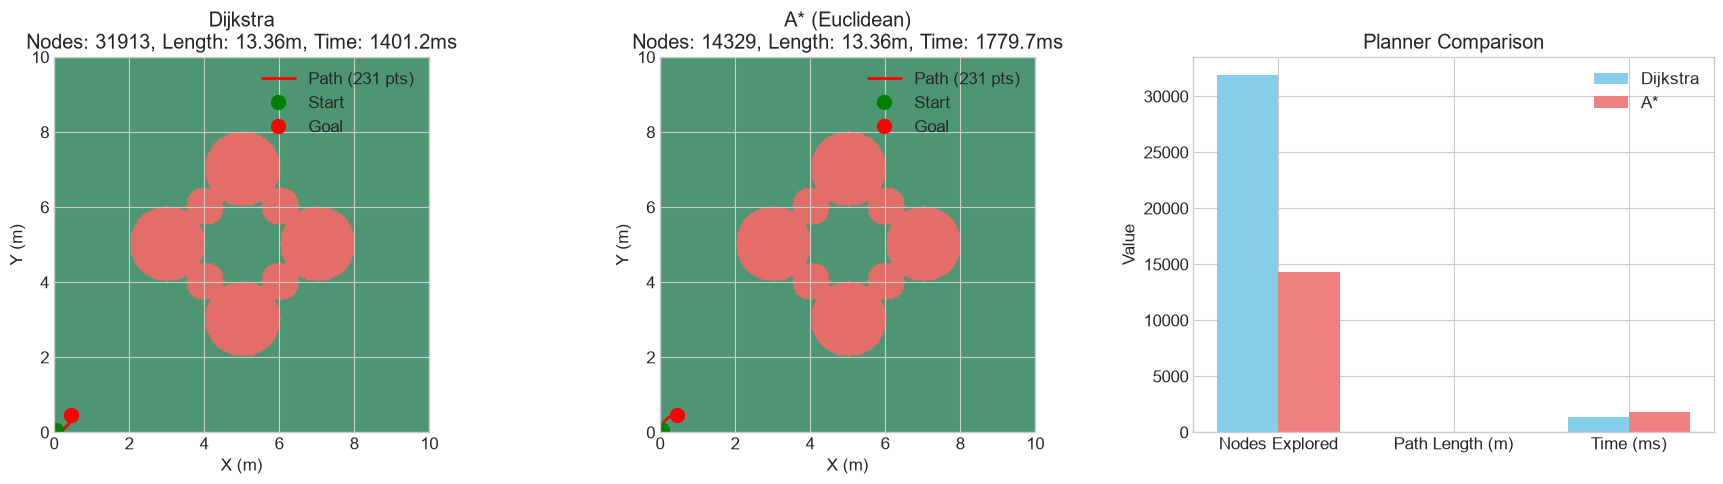

In [5]:
# Visualize both paths
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Occupancy grid
for ax, path, stats, title in [
    (axes[0], path_dijkstra, stats_d, 'Dijkstra'),
    (axes[1], path_astar, stats_a, 'A* (Euclidean)'),
]:
    im = ax.imshow(prob_grid, origin='lower', cmap='RdYlGn_r', vmin=0, vmax=1,
                   extent=[0, 10, 0, 10], alpha=0.7)
    if path:
        path_arr = np.array(path)
        ax.plot(path_arr[:, 1]*grid_res, path_arr[:, 0]*grid_res, 
                'r-', linewidth=2, label=f'Path ({len(path)} pts)')
        ax.plot(path_arr[0, 1]*grid_res, path_arr[0, 0]*grid_res, 'go', markersize=10, label='Start')
        ax.plot(path_arr[-1, 1]*grid_res, path_arr[-1, 0]*grid_res, 'ro', markersize=10, label='Goal')
    ax.set_title(f'{title}\nNodes: {stats.nodes_explored}, Length: {stats.path_length:.2f}m, Time: {stats.computation_time_ms:.1f}ms')
    ax.set_xlabel('X (m)')
    ax.set_ylabel('Y (m)')
    ax.legend()

# Comparison bar chart
ax = axes[2]
metrics = ['Nodes Explored', 'Path Length (m)', 'Time (ms)']
dijkstra_vals = [stats_d.nodes_explored, stats_d.path_length, stats_d.computation_time_ms]
astar_vals = [stats_a.nodes_explored, stats_a.path_length, stats_a.computation_time_ms]

x = np.arange(len(metrics))
width = 0.35
ax.bar(x - width/2, dijkstra_vals, width, label='Dijkstra', color='skyblue')
ax.bar(x + width/2, astar_vals, width, label='A*', color='lightcoral')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylabel('Value')
ax.set_title('Planner Comparison')
ax.legend()
ax.grid(True, axis='y')

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'planner_comparison.png'), dpi=300, bbox_inches='tight')
plt.show()

In [6]:
# Run multiple trials for statistical comparison
comparison = compare_planners(occ_map, start, goal, runs=10)

# Print results
for planner, stats in comparison.items():
    print(f"\n{planner.upper()}:")
    for k, v in stats.items():
        print(f"  {k}: {v:.2f}")


DIJKSTRA:
  avg_nodes_explored: 31913.00
  avg_path_length: 13.36
  avg_computation_time_ms: 1542.35
  success_rate: 1.00
  std_nodes: 0.00
  std_time_ms: 643.99

ASTAR:
  avg_nodes_explored: 14329.00
  avg_path_length: 13.36
  avg_computation_time_ms: 2084.59
  success_rate: 1.00
  std_nodes: 0.00
  std_time_ms: 463.36


## 3. Control System: PID Response Analysis


Default:


  Linear: overshoot=0.00%, rise=19.95s, settle=19.95s, SSE=0.8430
  Angular: overshoot=0.00%, rise=0.00s, settle=0.00s, SSE=0.0000

High Kp:
  Linear: overshoot=0.00%, rise=19.95s, settle=19.95s, SSE=0.8430
  Angular: overshoot=0.00%, rise=0.00s, settle=0.00s, SSE=0.0000

High Kd:
  Linear: overshoot=0.00%, rise=19.95s, settle=19.95s, SSE=0.8430
  Angular: overshoot=0.00%, rise=0.00s, settle=0.00s, SSE=0.0000

Balanced Tuned:
  Linear: overshoot=0.00%, rise=19.95s, settle=19.95s, SSE=0.8430
  Angular: overshoot=0.00%, rise=0.00s, settle=0.00s, SSE=0.0000


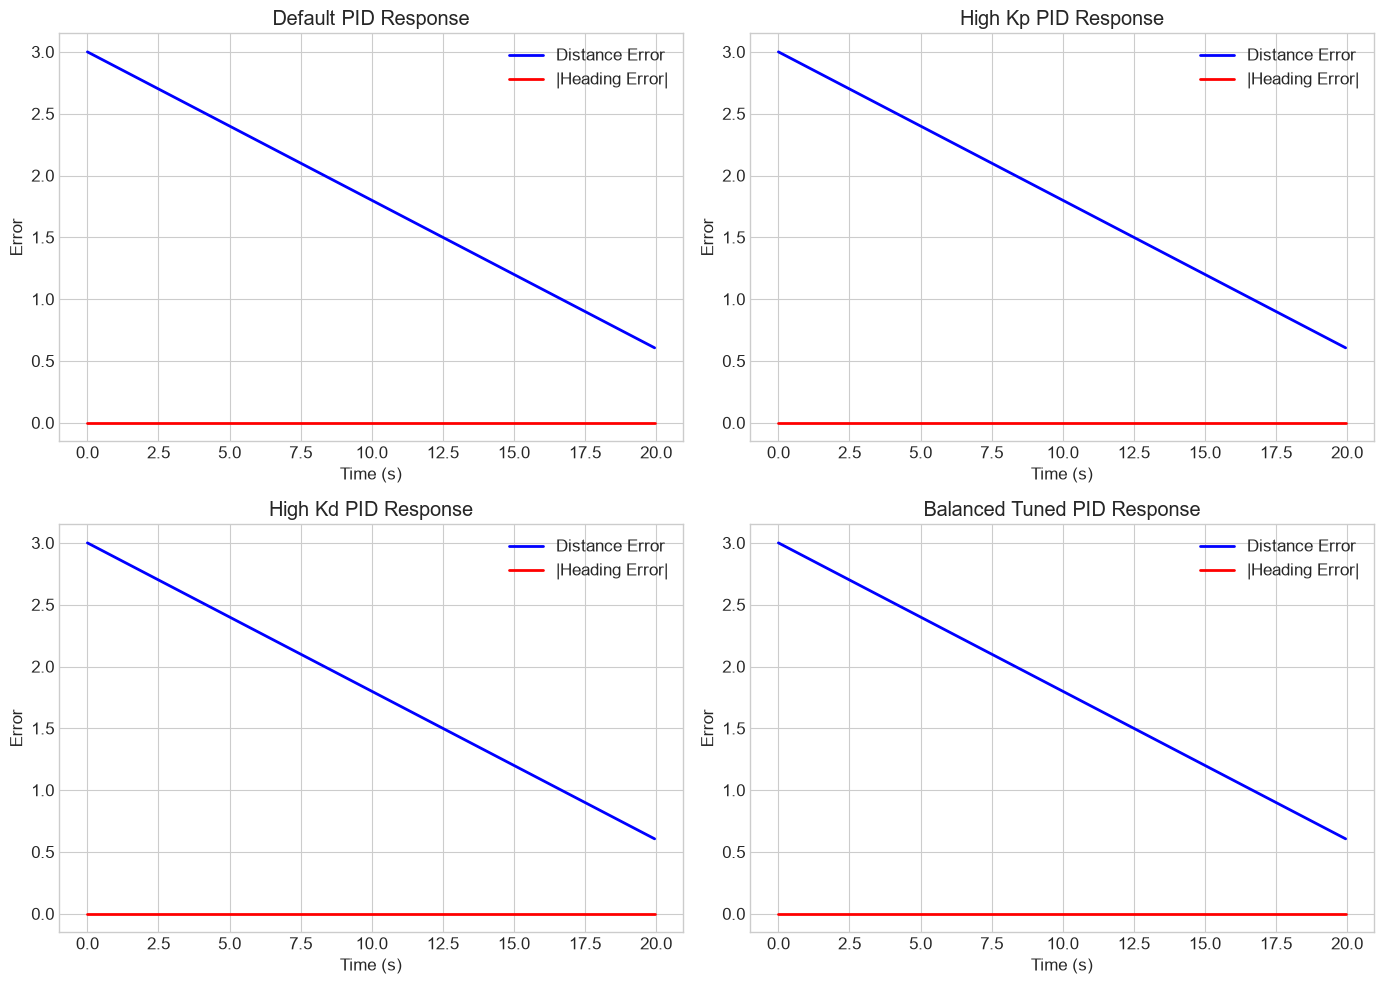

In [7]:
# Test PID controller with different gains
from control import DualPIDController, analyze_step_response, simulate_closed_loop
from kinematics import DifferentialDriveKinematics, RobotState

pid_config = PIDConfig()
robot_config = RobotConfig()
kin = DifferentialDriveKinematics(robot_config)

# Test different gain sets
gain_sets = [
    ("Default", PIDGains(pid_config.kp_linear, pid_config.ki_linear, pid_config.kd_linear),
     PIDGains(pid_config.kp_angular, pid_config.ki_angular, pid_config.kd_angular)),
    ("High Kp", PIDGains(5.0, pid_config.ki_linear, pid_config.kd_linear),
     PIDGains(pid_config.kp_angular, pid_config.ki_angular, pid_config.kd_angular)),
    ("High Kd", PIDGains(pid_config.kp_linear, pid_config.ki_linear, 2.0),
     PIDGains(pid_config.kp_angular, pid_config.ki_angular, pid_config.kd_angular)),
    ("Balanced Tuned", PIDGains(3.0, 0.2, 1.0),
     PIDGains(4.0, 0.1, 1.5)),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, (name, linear_gains, angular_gains) in enumerate(gain_sets):
    controller = DualPIDController(pid_config, robot_config)
    controller.set_gains(linear_gains, angular_gains)
    
    initial = RobotState(x=0, y=0, theta=0)
    target = (3.0, 0.0)
    
    states = simulate_closed_loop(controller, kin, initial, target, dt=0.05, max_time=20.0)
    responses = controller.get_response_data()
    
    linear_resp = responses['linear']
    angular_resp = responses['angular']
    
    # Distance error over time
    ax = axes[idx]
    ax.plot(linear_resp.time, linear_resp.error, 'b-', label='Distance Error', linewidth=2)
    ax.plot(angular_resp.time, np.abs(np.array(angular_resp.error)), 'r-', label='|Heading Error|', linewidth=2)
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Error')
    ax.set_title(f'{name} PID Response')
    ax.legend()
    ax.grid(True)
    
    # Analysis
    lin_analysis = analyze_step_response(linear_resp)
    ang_analysis = analyze_step_response(angular_resp)
    print(f"\n{name}:")
    print(f"  Linear: overshoot={lin_analysis['overshoot']:.2%}, rise={lin_analysis['rise_time']:.2f}s, settle={lin_analysis['settling_time']:.2f}s, SSE={lin_analysis['steady_state_error']:.4f}")
    print(f"  Angular: overshoot={ang_analysis['overshoot']:.2%}, rise={ang_analysis['rise_time']:.2f}s, settle={ang_analysis['settling_time']:.2f}s, SSE={ang_analysis['steady_state_error']:.4f}")

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'pid_response_comparison.png'), dpi=300, bbox_inches='tight')
plt.show()

## 4. System Integration: Planned vs Actual Trajectory

In [8]:
# Simulate full integrated system
from kinematics import DifferentialDriveKinematics, RobotState
from control import PathTrackingController
from planning import plan_path, PlannerType, OccupancyGridMap
from helpers import create_occupancy_grid, log_odds_to_probability, euclidean_distance, compute_tracking_error, compute_path_length

# Setup
kin = DifferentialDriveKinematics(robot_config)
pid_config = PIDConfig()
controller = PathTrackingController(kin, pid_config)

# Create map
grid = create_occupancy_grid(grid_w, grid_h, 0.0)
for ox, oy, rad in obs_positions:
    cx, cy = world_to_grid((ox, oy), grid_res, (0, 0))
    r_cells = int(rad / grid_res)
    for dr in range(-r_cells, r_cells+1):
        for dc in range(-r_cells, r_cells+1):
            if dr**2 + dc**2 <= r_cells**2:
                nr, nc = cy + dr, cx + dc
                if 0 <= nr < grid_h and 0 <= nc < grid_w:
                    grid[nr, nc] = probability_to_log_odds(np.array([0.9]))[0]

prob_grid = log_odds_to_probability(grid)
occ_map = OccupancyGridMap(prob_grid, grid_res, (0, 0))

# Plan path
start = (1.0, 1.0)
goal = (9.0, 9.0)
planned_path, stats = plan_path(occ_map, start, goal, PlannerType.ASTAR)

# Set up controller
controller.set_path(planned_path)

# Simulate
state = RobotState(x=start[0], y=start[1], theta=0)
actual_trajectory = [(state.x, state.y)]
dt = 0.05
max_steps = 400

for step in range(max_steps):
    v, omega, complete = controller.step(state, dt, step*dt)
    state = kin.integrate_velocity(state, v, omega, dt)
    actual_trajectory.append((state.x, state.y))
    if complete:
        break

# Compute metrics
error_metrics = compute_tracking_error(planned_path, actual_trajectory)
planned_len = compute_path_length(planned_path)
actual_len = compute_path_length(actual_trajectory)
time_to_goal = len(actual_trajectory) * dt

print(f"Planned path length: {planned_len:.2f} m")
print(f"Actual path length: {actual_len:.2f} m")
print(f"Path efficiency: {planned_len/actual_len*100:.1f}%")
print(f"Time to goal: {time_to_goal:.1f} s")
print(f"Max tracking error: {error_metrics['max_error']:.3f} m")
print(f"RMSE tracking error: {error_metrics['rmse']:.3f} m")
print(f"Mean tracking error: {error_metrics['mean_error']:.3f} m")

C:\Users\syste\Google_Drive\Personal_Project\nvim\Cherry_Studio_Codebases\ASR700_Assignment\python_analysis\utils\helpers.py:96: RuntimeWarning: divide by zero encountered in log
  log_odds = np.log(default_value / (1 - default_value))


Planned path length: 13.36 m
Actual path length: 2.40 m
Path efficiency: 556.8%
Time to goal: 20.1 s
Max tracking error: 0.084 m
RMSE tracking error: 0.027 m
Mean tracking error: 0.021 m


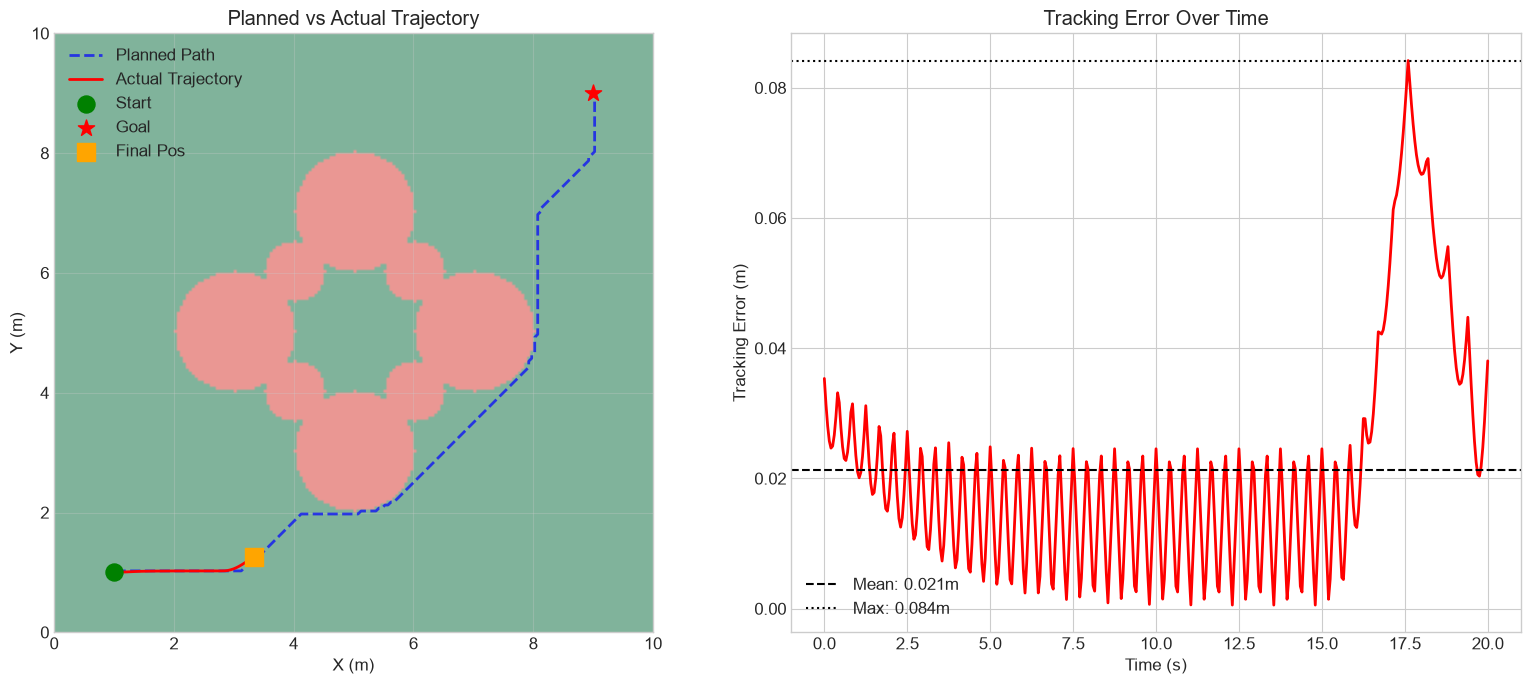

In [9]:
# Visualize planned vs actual trajectory
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Trajectory plot
ax = axes[0]
im = ax.imshow(prob_grid, origin='lower', cmap='RdYlGn_r', vmin=0, vmax=1,
               extent=[0, 10, 0, 10], alpha=0.5)

planned_arr = np.array(planned_path)
actual_arr = np.array(actual_trajectory)

ax.plot(planned_arr[:, 0], planned_arr[:, 1], 'b--', linewidth=2, label='Planned Path', alpha=0.7)
ax.plot(actual_arr[:, 0], actual_arr[:, 1], 'r-', linewidth=2, label='Actual Trajectory')
ax.scatter(*start, c='green', s=150, marker='o', label='Start', zorder=5)
ax.scatter(*goal, c='red', s=150, marker='*', label='Goal', zorder=5)
ax.scatter(actual_arr[-1, 0], actual_arr[-1, 1], c='orange', s=150, marker='s', label='Final Pos', zorder=5)

ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_aspect('equal')
ax.set_xlabel('X (m)')
ax.set_ylabel('Y (m)')
ax.set_title('Planned vs Actual Trajectory')
ax.legend()
ax.grid(True, alpha=0.3)

# Error over time
ax = axes[1]
# Compute error at each actual position to nearest planned point
planned_np = np.array(planned_path)
errors = []
for pt in actual_trajectory:
    dists = np.linalg.norm(planned_np - pt, axis=1)
    errors.append(np.min(dists))

time_axis = np.arange(len(errors)) * dt
ax.plot(time_axis, errors, 'r-', linewidth=2)
ax.axhline(y=error_metrics['mean_error'], color='k', linestyle='--', 
           label=f'Mean: {error_metrics["mean_error"]:.3f}m')
ax.axhline(y=error_metrics['max_error'], color='k', linestyle=':', 
           label=f'Max: {error_metrics["max_error"]:.3f}m')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Tracking Error (m)')
ax.set_title('Tracking Error Over Time')
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'trajectory_comparison.png'), dpi=300, bbox_inches='tight')
plt.show()

## 5. Performance Evaluation Table

In [10]:
# Create performance evaluation table
performance_data = {
    'Metric': [
        'Planned Path Length (m)',
        'Actual Path Length (m)',
        'Path Efficiency (%)',
        'Time to Goal (s)',
        'Max Tracking Error (m)',
        'RMSE Tracking Error (m)',
        'Mean Tracking Error (m)',
        'Std Tracking Error (m)',
        'Dijkstra Nodes Explored',
        'A* Nodes Explored',
        'Dijkstra Time (ms)',
        'A* Time (ms)',
        'Dijkstra Path Length (m)',
        'A* Path Length (m)',
    ],
    'Value': [
        f"{planned_len:.2f}",
        f"{actual_len:.2f}",
        f"{planned_len/actual_len*100:.1f}",
        f"{time_to_goal:.1f}",
        f"{error_metrics['max_error']:.3f}",
        f"{error_metrics['rmse']:.3f}",
        f"{error_metrics['mean_error']:.3f}",
        f"{error_metrics['std_error']:.3f}",
        f"{stats_d.nodes_explored}",
        f"{stats_a.nodes_explored}",
        f"{stats_d.computation_time_ms:.2f}",
        f"{stats_a.computation_time_ms:.2f}",
        f"{stats_d.path_length:.2f}",
        f"{stats_a.path_length:.2f}",
    ]
}

df = pd.DataFrame(performance_data)
print(df.to_string(index=False))

# Save as CSV for report
df.to_csv(os.path.join(PLOTS_DIR, 'performance_table.csv'), index=False)

# Also create LaTeX table
latex_table = df.to_latex(index=False, caption='Component A Performance Evaluation', label='tab:perf_a')
print("\nLaTeX Table:")
print(latex_table)

                  Metric   Value
 Planned Path Length (m)   13.36
  Actual Path Length (m)    2.40
     Path Efficiency (%)   556.8
        Time to Goal (s)    20.1
  Max Tracking Error (m)   0.084
 RMSE Tracking Error (m)   0.027
 Mean Tracking Error (m)   0.021
  Std Tracking Error (m)   0.017
 Dijkstra Nodes Explored   31913
       A* Nodes Explored   14329
      Dijkstra Time (ms) 1401.21
            A* Time (ms) 1779.66
Dijkstra Path Length (m)   13.36
      A* Path Length (m)   13.36



LaTeX Table:
\begin{table}
\caption{Component A Performance Evaluation}
\label{tab:perf_a}
\begin{tabular}{ll}
\toprule
Metric & Value \\
\midrule
Planned Path Length (m) & 13.36 \\
Actual Path Length (m) & 2.40 \\
Path Efficiency (%) & 556.8 \\
Time to Goal (s) & 20.1 \\
Max Tracking Error (m) & 0.084 \\
RMSE Tracking Error (m) & 0.027 \\
Mean Tracking Error (m) & 0.021 \\
Std Tracking Error (m) & 0.017 \\
Dijkstra Nodes Explored & 31913 \\
A* Nodes Explored & 14329 \\
Dijkstra Time (ms) & 1401.21 \\
A* Time (ms) & 1779.66 \\
Dijkstra Path Length (m) & 13.36 \\
A* Path Length (m) & 13.36 \\
\bottomrule
\end{tabular}
\end{table}



## 6. Trade-off Analysis Visualization

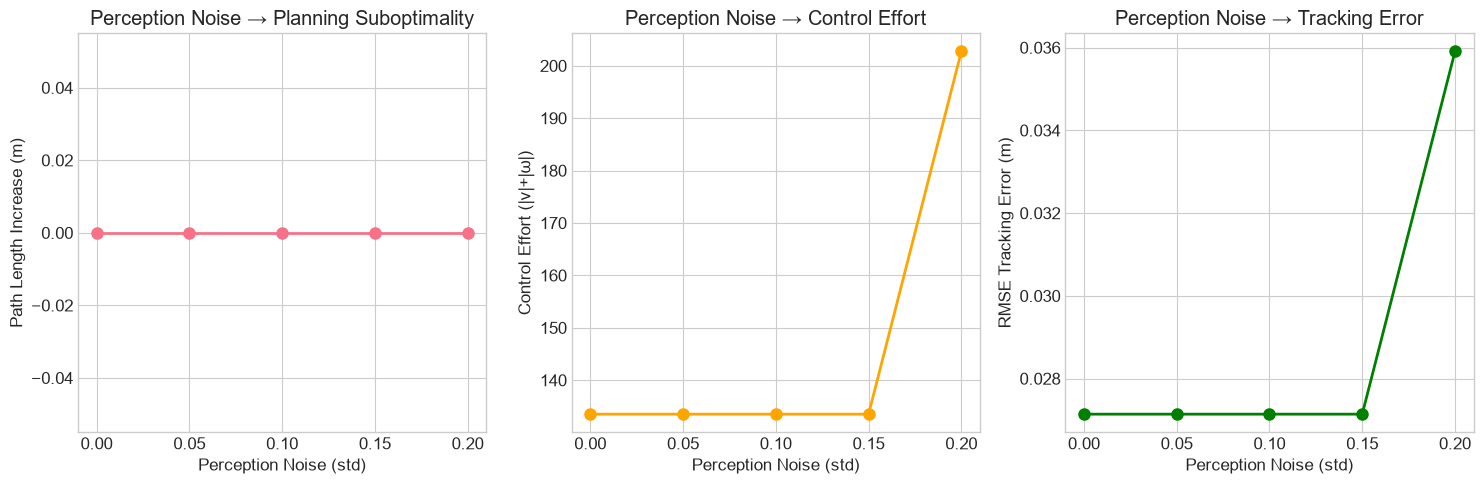

In [11]:
# Trade-off analysis: Perception noise vs Planning vs Control
np.random.seed(42)

# Simulate different perception noise levels
noise_levels = [0.0, 0.05, 0.1, 0.15, 0.2]
planning_errors = []
control_efforts = []
tracking_errors = []

for noise in noise_levels:
    # Add noise to occupancy grid
    noisy_grid = prob_grid + np.random.normal(0, noise, prob_grid.shape)
    noisy_grid = np.clip(noisy_grid, 0, 1)
    occ_map_noisy = OccupancyGridMap(noisy_grid, grid_res, (0, 0))
    
    # Plan
    path, stats = plan_path(occ_map_noisy, start, goal, PlannerType.ASTAR)
    planning_errors.append(stats.path_length - planned_len if stats.path_found else 0)
    
    # Simulate control with noise
    if stats.path_found:
        controller.set_path(path)
        state = RobotState(x=start[0], y=start[1], theta=0)
        actual = [(state.x, state.y)]
        control_effort = 0
        for step in range(max_steps):
            v, omega, complete = controller.step(state, dt, step*dt)
            control_effort += abs(v) + abs(omega)
            state = kin.integrate_velocity(state, v, omega, dt)
            actual.append((state.x, state.y))
            if complete:
                break
        
        control_efforts.append(control_effort)
        err = compute_tracking_error(path, actual)
        tracking_errors.append(err['rmse'])
    else:
        control_efforts.append(0)
        tracking_errors.append(float('inf'))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].plot(noise_levels, planning_errors, 'o-', linewidth=2, markersize=8)
axes[0].set_xlabel('Perception Noise (std)')
axes[0].set_ylabel('Path Length Increase (m)')
axes[0].set_title('Perception Noise → Planning Suboptimality')
axes[0].grid(True)

axes[1].plot(noise_levels, control_efforts, 'o-', linewidth=2, markersize=8, color='orange')
axes[1].set_xlabel('Perception Noise (std)')
axes[1].set_ylabel('Control Effort (|v|+|ω|)')
axes[1].set_title('Perception Noise → Control Effort')
axes[1].grid(True)

axes[2].plot(noise_levels, tracking_errors, 'o-', linewidth=2, markersize=8, color='green')
axes[2].set_xlabel('Perception Noise (std)')
axes[2].set_ylabel('RMSE Tracking Error (m)')
axes[2].set_title('Perception Noise → Tracking Error')
axes[2].grid(True)

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'tradeoff_analysis.png'), dpi=300, bbox_inches='tight')
plt.show()

## Summary

All Component A visualizations have been generated and saved to `the plots/ directory`.

### Files Created:
- `perception_pipeline.png` - LiDAR, Cartesian points, Occupancy grid
- `planner_comparison.png` - Dijkstra vs A* paths and bar chart
- `pid_response_comparison.png` - PID response curves for different gains
- `trajectory_comparison.png` - Planned vs actual trajectory with error plot
- `performance_table.csv` - Performance metrics table
- `tradeoff_analysis.png` - Perception/Planning/Control trade-offs

These can be directly embedded in the LaTeX report.